# Solution 2: Log-Mel Spectrogram Convolutional Neural Network

This notebook implements the second environmental sound classification solution using a Convolutional Neural Network, or CNN.

Each ESC-50 recording is converted into a two-dimensional log-mel spectrogram. The spectrogram represents:

- Time on the horizontal axis
- Mel-frequency bands on the vertical axis
- Audio energy through pixel intensity

A small CNN learns visual patterns from these spectrograms.

The solution is evaluated using the five official ESC-50 folds under the following recording conditions:

- Clean
- 20 dB SNR
- 10 dB SNR
- 5 dB SNR
- 0 dB SNR

## 1. Install PyTorch

PyTorch is required to create and train the CNN.

This installation cell only needs to be run once. The notebook kernel should be restarted after installation.

In [15]:
%pip install torch

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Imports and configuration

The CNN is intentionally kept small so that it can be trained on a normal laptop.

The experiment uses:

- 16,000 Hz audio
- 64 Mel-frequency bands
- 160 spectrogram time frames
- Five official ESC-50 folds
- Eight training epochs per fold

In [16]:
from pathlib import Path
import json
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import soundfile as sf
import torch
import torch.nn as nn

from scipy.signal import resample_poly, stft
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from torch.utils.data import DataLoader, Dataset, TensorDataset
from tqdm.auto import tqdm

import copy

RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

SAMPLE_RATE = 16000
N_MELS = 64

# the complete five-second spectrogram is resized rather than cropped
MAX_TIME_FRAMES = 256

BATCH_SIZE = 32

MAX_EPOCHS = 40
EARLY_STOPPING_PATIENCE = 7

LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

DATASET_ROOT = PROJECT_ROOT / "data" / "ESC-50"
AUDIO_DIR = DATASET_ROOT / "audio"
METADATA_PATH = DATASET_ROOT / "meta" / "esc50.csv"

OUTPUT_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "solution2_spectrogram_cnn"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

sns.set_theme(style="whitegrid")

print("PyTorch version:", torch.__version__)
print("Training device:", DEVICE)
print("Metadata found:", METADATA_PATH.exists())
print("Audio folder found:", AUDIO_DIR.exists())

PyTorch version: 2.11.0+cpu
Training device: cpu
Metadata found: True
Audio folder found: True


## 3. Load ESC-50 metadata

ESC-50 contains 2,000 five-second environmental sound recordings from 50 classes.

The official folds are retained throughout the experiment.

In [17]:
assert METADATA_PATH.exists(), (
    f"Metadata file not found: {METADATA_PATH}"
)

assert AUDIO_DIR.exists(), (
    f"Audio folder not found: {AUDIO_DIR}"
)

metadata = pd.read_csv(
    METADATA_PATH
)

metadata = (
    metadata
    .sort_values(["fold", "filename"])
    .reset_index(drop=True)
)

assert len(metadata) == 2000
assert metadata["category"].nunique() == 50

class_names = (
    metadata[
        ["target", "category"]
    ]
    .drop_duplicates()
    .sort_values("target")["category"]
    .tolist()
)

y = metadata["target"].to_numpy(
    dtype=np.int64
)

folds = metadata["fold"].to_numpy(
    dtype=np.int64
)

display(metadata.head())

print("Recordings:", len(metadata))
print("Classes:", len(class_names))
print("Folds:", sorted(np.unique(folds)))

,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A


Recordings: 2000
Classes: 50
Folds: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


## 4. Log-mel spectrogram extraction

Each audio recording is converted into a log-mel spectrogram.

The processing steps are:

1. Load the recording.
2. Convert stereo audio to mono.
3. Resample it to 16,000 Hz.
4. Normalize the amplitude.
5. Calculate the Short-Time Fourier Transform.
6. Apply a Mel-frequency filter bank.
7. Convert energy values to a logarithmic scale.
8. Standardize the spectrogram.
9. Crop or pad it to 160 time frames.

The resulting CNN input has a fixed shape of 64 by 160.

In [18]:
def hz_to_mel(frequency):
    return 2595.0 * np.log10(
        1.0 + frequency / 700.0
    )


def mel_to_hz(mel):
    return 700.0 * (
        10.0 ** (mel / 2595.0) - 1.0
    )


def create_mel_filterbank(
    sample_rate,
    n_fft,
    n_mels=N_MELS,
):
    mel_points = np.linspace(
        hz_to_mel(0),
        hz_to_mel(sample_rate / 2),
        n_mels + 2,
    )

    frequency_points = mel_to_hz(
        mel_points
    )

    bins = np.floor(
        (n_fft + 1)
        * frequency_points
        / sample_rate
    ).astype(int)

    filters = np.zeros(
        (
            n_mels,
            n_fft // 2 + 1,
        )
    )

    for index in range(
        1,
        n_mels + 1,
    ):
        left = bins[index - 1]
        center = bins[index]
        right = bins[index + 1]

        if center > left:
            filters[
                index - 1,
                left:center,
            ] = (
                np.arange(left, center) - left
            ) / (center - left)

        if right > center:
            filters[
                index - 1,
                center:right,
            ] = (
                right - np.arange(center, right)
            ) / (right - center)

    return filters


def load_audio(
    audio_path,
    sample_rate=SAMPLE_RATE,
):
    signal, original_rate = sf.read(
        audio_path,
        dtype="float32",
        always_2d=False,
    )

    if signal.ndim == 2:
        signal = signal.mean(axis=1)

    if original_rate != sample_rate:
        common_factor = np.gcd(
            original_rate,
            sample_rate,
        )

        signal = resample_poly(
            signal,
            sample_rate // common_factor,
            original_rate // common_factor,
        )

    peak = np.max(np.abs(signal))

    if peak > 0:
        signal = signal / peak

    return signal.astype(np.float32)


def signal_to_log_mel(
    signal,
    sample_rate=SAMPLE_RATE,
):
    n_fft = 512

    _, _, spectrum = stft(
        signal,
        fs=sample_rate,
        window="hann",
        nperseg=400,
        noverlap=240,
        nfft=n_fft,
        boundary=None,
    )

    power = (
        np.abs(spectrum) ** 2
    ) / n_fft

    mel_filterbank = create_mel_filterbank(
        sample_rate,
        n_fft,
    )

    mel_spectrogram = (
        mel_filterbank @ power
    )

    log_mel = np.log10(
        np.maximum(
            mel_spectrogram,
            1e-10,
        )
    )

    # Standardize the spectrogram
    log_mel = (
        log_mel - log_mel.mean()
    ) / (
        log_mel.std() + 1e-8
    )

    # Resize the complete time axis instead of
    # cropping the beginning of the recording.
    original_time_positions = np.linspace(
        0.0,
        1.0,
        log_mel.shape[1],
    )

    target_time_positions = np.linspace(
        0.0,
        1.0,
        MAX_TIME_FRAMES,
    )

    resized_log_mel = np.empty(
        (
            N_MELS,
            MAX_TIME_FRAMES,
        ),
        dtype=np.float32,
    )

    for mel_index in range(N_MELS):
        resized_log_mel[
            mel_index
        ] = np.interp(
            target_time_positions,
            original_time_positions,
            log_mel[mel_index],
        )

    # Return only after every Mel band is resized
    return resized_log_mel


def extract_spectrogram(
    audio_path,
):
    signal = load_audio(
        audio_path
    )

    return signal_to_log_mel(
        signal
    )

## 5. Visualize an example spectrogram

This plot demonstrates how a five-second environmental sound is represented before it is supplied to the CNN.

Spectrogram shape: (64, 256)


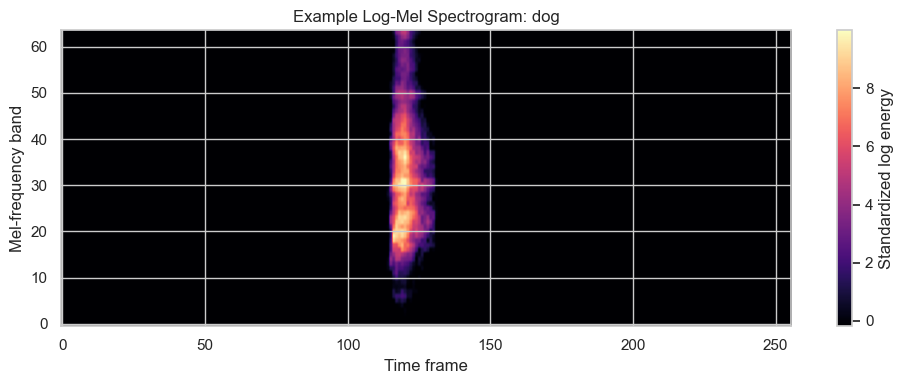

In [19]:
example_row = metadata.iloc[0]

example_spectrogram = extract_spectrogram(
    AUDIO_DIR / example_row["filename"]
)

print(
    "Spectrogram shape:",
    example_spectrogram.shape,
)

fig, ax = plt.subplots(
    figsize=(10, 4)
)

image = ax.imshow(
    example_spectrogram,
    origin="lower",
    aspect="auto",
    cmap="magma",
)

ax.set(
    title=(
        "Example Log-Mel Spectrogram: "
        + example_row["category"]
    ),
    xlabel="Time frame",
    ylabel="Mel-frequency band",
)

fig.colorbar(
    image,
    ax=ax,
    label="Standardized log energy",
)

plt.tight_layout()
plt.show()

## 6. Extract and cache clean spectrograms

All ESC-50 recordings are converted into spectrograms.

The extracted spectrograms are cached so they do not need to be recalculated whenever the notebook is run.

In [20]:
CLEAN_CACHE = (
    OUTPUT_DIR
    / "clean_log_mel_spectrograms_v2_64x256.npz"
)

if CLEAN_CACHE.exists():
    cached = np.load(
        CLEAN_CACHE
    )

    X_clean = cached["X"]

    print(
        "Loaded cached clean spectrograms."
    )

else:
    spectrogram_rows = []

    for filename in tqdm(
        metadata["filename"],
        desc="Extracting clean spectrograms",
    ):
        spectrogram = extract_spectrogram(
            AUDIO_DIR / filename
        )

        spectrogram_rows.append(
            spectrogram
        )

    X_clean = np.asarray(
        spectrogram_rows,
        dtype=np.float32,
    )

    np.savez_compressed(
        CLEAN_CACHE,
        X=X_clean,
    )

    print(
        "Saved clean spectrogram cache:",
        CLEAN_CACHE,
    )

print(
    "Clean spectrogram dataset:",
    X_clean.shape,
)

Extracting clean spectrograms:   0%|          | 0/2000 [00:00<?, ?it/s]

Saved clean spectrogram cache: c:\Users\kashm\OneDrive\Desktop\noise-robust-esc50\outputs\solution2_spectrogram_cnn\clean_log_mel_spectrograms_v2_64x256.npz
Clean spectrogram dataset: (2000, 64, 256)


## 7. Improved spectrogram CNN

The improved CNN contains four convolutional blocks with 32, 64, 128, and 256 channels.

Each block uses:

- A convolutional layer
- Batch normalization
- ReLU activation
- Max pooling
- Spatial dropout

The larger channel capacity allows the network to learn more detailed time-frequency patterns.

Global average pooling reduces the final feature maps before classification. This uses considerably fewer parameters than connecting the complete feature map to a dense layer, reducing the risk of overfitting.

In [21]:
class SpectrogramCNN(nn.Module):

    def __init__(
        self,
        number_of_classes=50,
    ):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(
                1,
                32,
                kernel_size=3,
                padding=1,
                bias=False,
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.10),

            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                padding=1,
                bias=False,
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.15),

            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                padding=1,
                bias=False,
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.20),

            nn.Conv2d(
                128,
                256,
                kernel_size=3,
                padding=1,
                bias=False,
            ),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.25),

            nn.AdaptiveAvgPool2d(
                (1, 1)
            ),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.40),
            nn.Linear(
                256,
                number_of_classes,
            ),
        )

    def forward(self, inputs):
        features = self.features(
            inputs
        )

        return self.classifier(
            features
        )


test_model = SpectrogramCNN().to(
    DEVICE
)

test_input = torch.zeros(
    2,
    1,
    N_MELS,
    MAX_TIME_FRAMES,
).to(DEVICE)

test_output = test_model(
    test_input
)

number_of_parameters = sum(
    parameter.numel()
    for parameter in test_model.parameters()
    if parameter.requires_grad
)

print(
    "CNN output shape:",
    test_output.shape,
)

print(
    "Trainable parameters:",
    f"{number_of_parameters:,}",
)

CNN output shape: torch.Size([2, 50])
Trainable parameters: 401,170


## 8. Training-only augmentation and early stopping

Spectrogram augmentation is applied only to the training recordings.

The augmentations include:

- Random time shifting
- Time masking
- Frequency masking
- Low-level Gaussian perturbation

Validation and test spectrograms are never augmented.

Early stopping monitors validation loss. The checkpoint with the lowest validation loss is retained, preventing the model from continuing to train after validation performance stops improving.

In [22]:
class SpectrogramDataset(Dataset):

    def __init__(
        self,
        features,
        labels,
        augment=False,
    ):
        self.features = features
        self.labels = labels
        self.augment = augment

    def __len__(self):
        return len(self.labels)

    def __getitem__(
        self,
        index,
    ):
        spectrogram = self.features[
            index
        ].copy()

        label = int(
            self.labels[index]
        )

        if self.augment:

            # Random time shift
            if np.random.random() < 0.5:
                maximum_shift = 24

                shift = np.random.randint(
                    -maximum_shift,
                    maximum_shift + 1,
                )

                spectrogram = np.roll(
                    spectrogram,
                    shift=shift,
                    axis=1,
                )

            # Frequency masking
            if np.random.random() < 0.5:
                mask_width = np.random.randint(
                    1,
                    9,
                )

                mask_start = np.random.randint(
                    0,
                    N_MELS - mask_width + 1,
                )

                spectrogram[
                    mask_start:
                    mask_start + mask_width,
                    :,
                ] = 0.0

            # Time masking
            if np.random.random() < 0.5:
                mask_width = np.random.randint(
                    4,
                    33,
                )

                mask_start = np.random.randint(
                    0,
                    MAX_TIME_FRAMES
                    - mask_width
                    + 1,
                )

                spectrogram[
                    :,
                    mask_start:
                    mask_start + mask_width,
                ] = 0.0

            # Small training-only Gaussian perturbation
            if np.random.random() < 0.4:
                noise_strength = (
                    np.random.uniform(
                        0.005,
                        0.03,
                    )
                )

                spectrogram += (
                    np.random.normal(
                        0.0,
                        noise_strength,
                        size=spectrogram.shape,
                    )
                    .astype(np.float32)
                )

        spectrogram_tensor = (
            torch.from_numpy(
                spectrogram[None, :, :]
            )
            .float()
        )

        return (
            spectrogram_tensor,
            torch.tensor(
                label,
                dtype=torch.long,
            ),
        )


def make_data_loader(
    features,
    labels,
    shuffle,
    augment=False,
):
    dataset = SpectrogramDataset(
        features,
        labels,
        augment=augment,
    )

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=(
            DEVICE.type == "cuda"
        ),
    )


def evaluate_loader(
    model,
    data_loader,
    loss_function,
):
    model.eval()

    total_loss = 0.0
    correct_predictions = 0
    total_examples = 0

    with torch.no_grad():
        for batch_X, batch_y in data_loader:
            batch_X = batch_X.to(
                DEVICE
            )

            batch_y = batch_y.to(
                DEVICE
            )

            logits = model(
                batch_X
            )

            loss = loss_function(
                logits,
                batch_y,
            )

            total_loss += (
                loss.item()
                * batch_X.size(0)
            )

            correct_predictions += (
                logits.argmax(dim=1)
                == batch_y
            ).sum().item()

            total_examples += (
                batch_y.size(0)
            )

    return (
        total_loss / total_examples,
        correct_predictions / total_examples,
    )


def train_with_validation(
    X_train,
    y_train,
    X_validation,
    y_validation,
):
    """
    Select the best epoch using validation loss.
    The official test fold is not used here.
    """

    model = SpectrogramCNN(
        number_of_classes=50
    ).to(DEVICE)

    training_loader = make_data_loader(
        X_train,
        y_train,
        shuffle=True,
        augment=True,
    )

    validation_loader = make_data_loader(
        X_validation,
        y_validation,
        shuffle=False,
        augment=False,
    )

    loss_function = (
        nn.CrossEntropyLoss(
            label_smoothing=0.05
        )
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )

    scheduler = (
        torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode="min",
            factor=0.5,
            patience=2,
            min_lr=1e-5,
        )
    )

    best_validation_loss = np.inf
    best_model_state = None
    best_epoch = 1
    epochs_without_improvement = 0

    history = []

    for epoch in range(
        1,
        MAX_EPOCHS + 1,
    ):
        model.train()

        total_training_loss = 0.0
        correct_training_predictions = 0
        total_training_examples = 0

        for batch_X, batch_y in training_loader:
            batch_X = batch_X.to(
                DEVICE
            )

            batch_y = batch_y.to(
                DEVICE
            )

            optimizer.zero_grad()

            logits = model(
                batch_X
            )

            loss = loss_function(
                logits,
                batch_y,
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=5.0,
            )

            optimizer.step()

            total_training_loss += (
                loss.item()
                * batch_X.size(0)
            )

            correct_training_predictions += (
                logits.argmax(dim=1)
                == batch_y
            ).sum().item()

            total_training_examples += (
                batch_y.size(0)
            )

        training_loss = (
            total_training_loss
            / total_training_examples
        )

        training_accuracy = (
            correct_training_predictions
            / total_training_examples
        )

        validation_loss, validation_accuracy = (
            evaluate_loader(
                model,
                validation_loader,
                loss_function,
            )
        )

        scheduler.step(
            validation_loss
        )

        current_learning_rate = (
            optimizer.param_groups[0]["lr"]
        )

        history.append(
            {
                "epoch": epoch,
                "training_loss": training_loss,
                "training_accuracy": training_accuracy,
                "validation_loss": validation_loss,
                "validation_accuracy": validation_accuracy,
                "learning_rate": current_learning_rate,
            }
        )

        print(
            f"Epoch {epoch:02d} | "
            f"train loss {training_loss:.4f} | "
            f"train acc {training_accuracy:.4f} | "
            f"val loss {validation_loss:.4f} | "
            f"val acc {validation_accuracy:.4f}"
        )

        if (
            validation_loss
            < best_validation_loss - 1e-4
        ):
            best_validation_loss = (
                validation_loss
            )

            best_model_state = copy.deepcopy(
                model.state_dict()
            )

            best_epoch = epoch

            epochs_without_improvement = 0

        else:
            epochs_without_improvement += 1

        if (
            epochs_without_improvement
            >= EARLY_STOPPING_PATIENCE
        ):
            print(
                "Early stopping triggered."
            )
            break

    model.load_state_dict(
        best_model_state
    )

    return (
        model,
        best_epoch,
        pd.DataFrame(history),
    )


def train_final_model(
    X_train,
    y_train,
    number_of_epochs,
):
    """
    Retrain a fresh model on all four non-test folds
    for the number of epochs selected using validation.
    """

    model = SpectrogramCNN(
        number_of_classes=50
    ).to(DEVICE)

    training_loader = make_data_loader(
        X_train,
        y_train,
        shuffle=True,
        augment=True,
    )

    loss_function = (
        nn.CrossEntropyLoss(
            label_smoothing=0.05
        )
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )

    for epoch in range(
        1,
        number_of_epochs + 1,
    ):
        model.train()

        for batch_X, batch_y in training_loader:
            batch_X = batch_X.to(
                DEVICE
            )

            batch_y = batch_y.to(
                DEVICE
            )

            optimizer.zero_grad()

            logits = model(
                batch_X
            )

            loss = loss_function(
                logits,
                batch_y,
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=5.0,
            )

            optimizer.step()

    return model


def predict_cnn(
    model,
    features,
):
    model.eval()

    dummy_labels = np.zeros(
        len(features),
        dtype=np.int64,
    )

    loader = make_data_loader(
        features,
        dummy_labels,
        shuffle=False,
        augment=False,
    )

    predictions = []

    with torch.no_grad():
        for batch_X, _ in loader:
            batch_X = batch_X.to(
                DEVICE
            )

            logits = model(
                batch_X
            )

            predictions.extend(
                logits.argmax(dim=1)
                .cpu()
                .numpy()
            )

    return np.asarray(
        predictions,
        dtype=np.int64,
    )

## 9. Nested validation and official five-fold evaluation

The official ESC-50 test fold remains completely excluded from model selection.

For every outer experiment:

1. One fold is held out for final testing.
2. One of the remaining folds is used for validation.
3. The other three folds are used for initial training.
4. Validation loss selects the best number of epochs.
5. A fresh model is trained on all four non-test folds for that number of epochs.
6. The final model is evaluated once on the official test fold.

This preserves all available non-test data for final model training while preventing the test fold from influencing early stopping.

In [23]:
clean_predictions = np.empty_like(y)

cnn_models = {}
training_histories = {}
clean_fold_results = []

for test_fold in sorted(
    np.unique(folds)
):
    validation_fold = (
        test_fold % 5
    ) + 1

    selection_training_mask = (
        (folds != test_fold)
        & (folds != validation_fold)
    )

    validation_mask = (
        folds == validation_fold
    )

    final_training_mask = (
        folds != test_fold
    )

    test_mask = (
        folds == test_fold
    )

    print("\n" + "=" * 70)

    print(
        f"Test fold: {test_fold} | "
        f"Validation fold: {validation_fold}"
    )

    print("=" * 70)

    started = time.perf_counter()

    _, best_epoch, history = (
        train_with_validation(
            X_clean[
                selection_training_mask
            ],
            y[
                selection_training_mask
            ],
            X_clean[
                validation_mask
            ],
            y[
                validation_mask
            ],
        )
    )

    print(
        f"Selected epoch: {best_epoch}"
    )

    # Retrain from scratch using every non-test fold
    model = train_final_model(
        X_clean[
            final_training_mask
        ],
        y[
            final_training_mask
        ],
        number_of_epochs=best_epoch,
    )

    fold_predictions = predict_cnn(
        model,
        X_clean[test_mask],
    )

    elapsed = (
        time.perf_counter()
        - started
    )

    clean_predictions[
        test_mask
    ] = fold_predictions

    cnn_models[
        int(test_fold)
    ] = model

    training_histories[
        int(test_fold)
    ] = history

    fold_accuracy = accuracy_score(
        y[test_mask],
        fold_predictions,
    )

    fold_macro_f1 = f1_score(
        y[test_mask],
        fold_predictions,
        average="macro",
        zero_division=0,
    )

    clean_fold_results.append(
        {
            "fold": int(test_fold),
            "validation_fold": int(
                validation_fold
            ),
            "selected_epoch": int(
                best_epoch
            ),
            "accuracy": fold_accuracy,
            "macro_f1": fold_macro_f1,
            "training_seconds": elapsed,
        }
    )

    print(
        f"Test accuracy: {fold_accuracy:.4f}"
    )

    print(
        f"Test macro F1: {fold_macro_f1:.4f}"
    )

    torch.save(
        model.state_dict(),
        OUTPUT_DIR
        / (
            "spectrogram_cnn_v2_"
            f"fold_{test_fold}.pt"
        ),
    )

clean_fold_results = pd.DataFrame(
    clean_fold_results
)

display(
    clean_fold_results.round(4)
)

print("Five-fold mean:")

display(
    clean_fold_results
    .mean(numeric_only=True)
    .to_frame("mean")
    .round(4)
)

clean_fold_results.to_csv(
    OUTPUT_DIR
    / "clean_fold_metrics_v2.csv",
    index=False,
)




Test fold: 1 | Validation fold: 2
Epoch 01 | train loss 3.8803 | train acc 0.0392 | val loss 3.4905 | val acc 0.1550
Epoch 02 | train loss 3.5125 | train acc 0.1108 | val loss 3.1770 | val acc 0.2375
Epoch 03 | train loss 3.2716 | train acc 0.1458 | val loss 2.9713 | val acc 0.2750
Epoch 04 | train loss 3.1009 | train acc 0.1775 | val loss 2.8942 | val acc 0.3050
Epoch 05 | train loss 2.9380 | train acc 0.2233 | val loss 2.7607 | val acc 0.3175
Epoch 06 | train loss 2.8836 | train acc 0.2342 | val loss 2.6563 | val acc 0.3800
Epoch 07 | train loss 2.7977 | train acc 0.2558 | val loss 2.6030 | val acc 0.3825
Epoch 08 | train loss 2.7262 | train acc 0.2542 | val loss 2.5344 | val acc 0.4025
Epoch 09 | train loss 2.6623 | train acc 0.2983 | val loss 2.5138 | val acc 0.3975
Epoch 10 | train loss 2.5584 | train acc 0.3183 | val loss 2.4426 | val acc 0.4050
Epoch 11 | train loss 2.5592 | train acc 0.3142 | val loss 2.3829 | val acc 0.4450
Epoch 12 | train loss 2.4894 | train acc 0.3450 | va

,fold,validation_fold,selected_epoch,accuracy,macro_f1,training_seconds
0,1,2,40,0.5875,0.5720,942.9657
1,2,3,40,0.6225,0.6081,981.4502
2,3,4,39,0.5875,0.5607,924.8971
3,4,5,39,0.6925,0.6785,914.5986
4,5,1,40,0.6325,0.6132,966.6274


Five-fold mean:


,mean
fold,3.0000
validation_fold,3.0000
selected_epoch,39.6000
accuracy,0.6245
macro_f1,0.6065
training_seconds,946.1078


## 10. Clean-audio confusion matrix and class-wise F1 scores

The clean-audio predictions establish the CNN baseline before background noise is introduced.

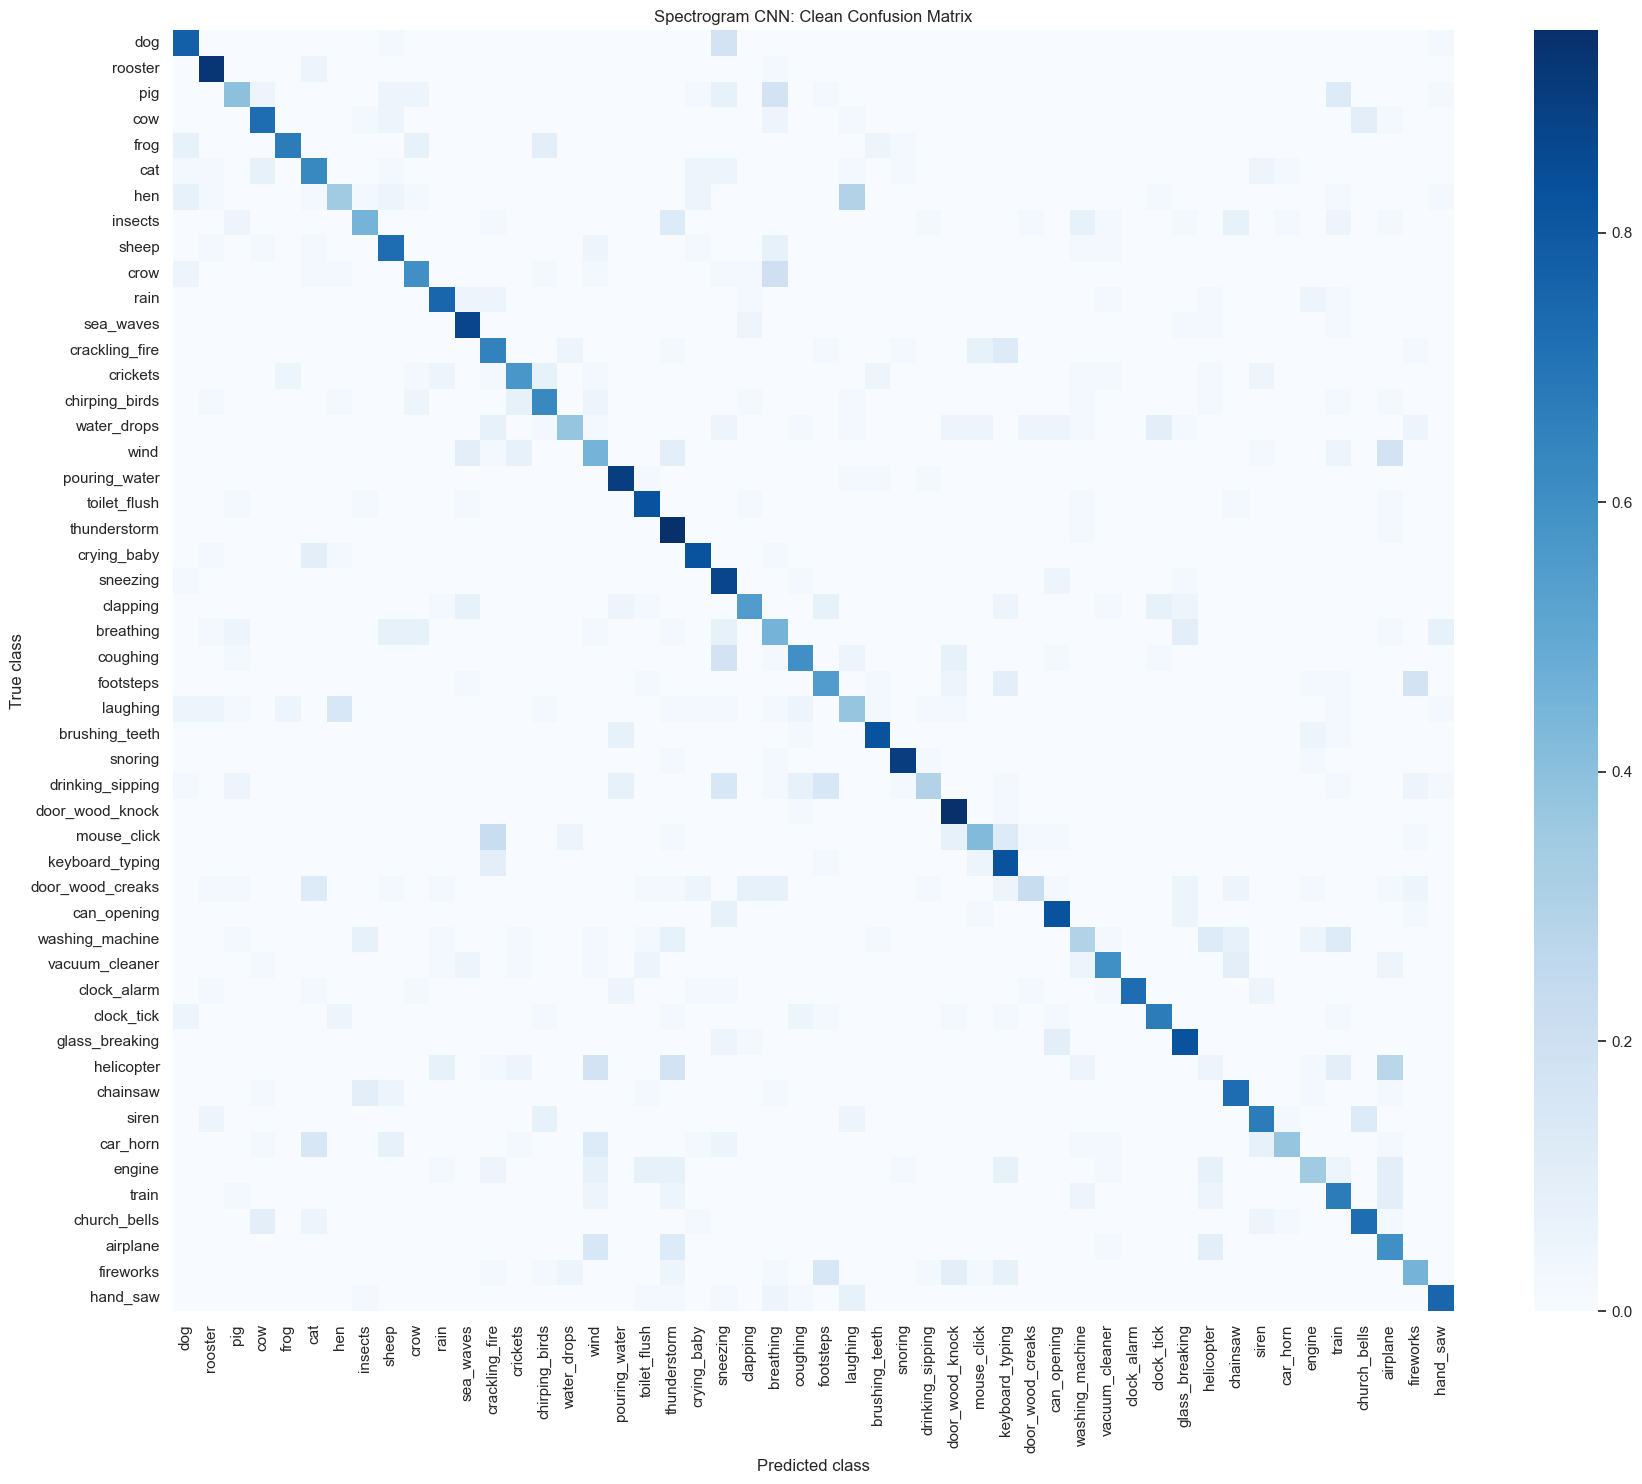

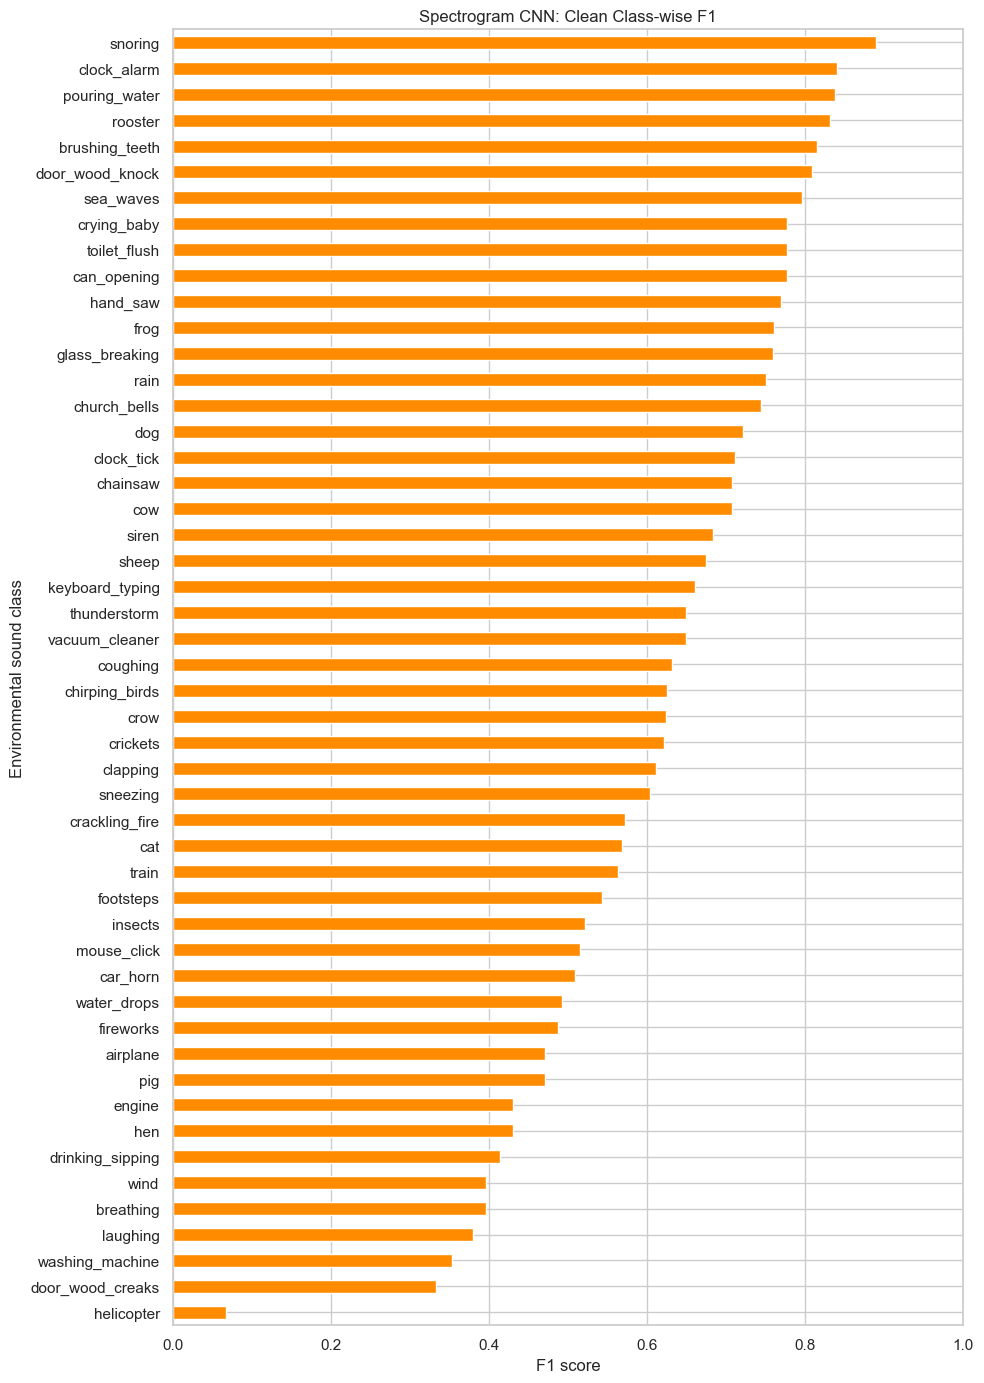

In [24]:
clean_report = classification_report(
    y,
    clean_predictions,
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)

clean_report_df = pd.DataFrame(
    clean_report
).T

clean_matrix = confusion_matrix(
    y,
    clean_predictions,
    normalize="true",
)

fig, ax = plt.subplots(
    figsize=(18, 15)
)

sns.heatmap(
    clean_matrix,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=ax,
)

ax.set(
    title="Spectrogram CNN: Clean Confusion Matrix",
    xlabel="Predicted class",
    ylabel="True class",
)

plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

fig.savefig(
    OUTPUT_DIR
    / "clean_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()


clean_class_f1 = (
    clean_report_df
    .loc[class_names, "f1-score"]
    .sort_values()
)

fig, ax = plt.subplots(
    figsize=(10, 14)
)

clean_class_f1.plot.barh(
    ax=ax,
    color="darkorange",
)

ax.set(
    title="Spectrogram CNN: Clean Class-wise F1",
    xlabel="F1 score",
    ylabel="Environmental sound class",
    xlim=(0, 1),
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR
    / "clean_classwise_f1.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

## 11. Generate noisy spectrograms

The clean-trained CNN is tested under four controlled Gaussian-noise conditions:

- 20 dB
- 10 dB
- 5 dB
- 0 dB

The same deterministic noise-generation rule used for the MFCC and SVM solution is applied here.

No CNN is retrained using noisy audio.

In [25]:
NOISE_RANDOM_SEED = 42
SNR_LEVELS = [20, 10, 5, 0]


def add_noise_at_snr(
    clean_signal,
    snr_db,
    random_generator,
):
    signal_power = np.mean(
        clean_signal ** 2
    )

    if signal_power == 0:
        return clean_signal.copy()

    raw_noise = random_generator.normal(
        loc=0.0,
        scale=1.0,
        size=len(clean_signal),
    ).astype(np.float32)

    raw_noise_power = np.mean(
        raw_noise ** 2
    )

    required_noise_power = (
        signal_power
        / (10 ** (snr_db / 10.0))
    )

    scale = np.sqrt(
        required_noise_power
        / raw_noise_power
    )

    noisy_signal = (
        clean_signal
        + raw_noise * scale
    )

    peak = np.max(
        np.abs(noisy_signal)
    )

    if peak > 1:
        noisy_signal = (
            noisy_signal / peak
        )

    return noisy_signal.astype(
        np.float32
    )


spectrogram_feature_sets = {
    "Clean": X_clean
}

for snr_db in SNR_LEVELS:
    condition_name = f"{snr_db} dB"

    cache_path = (
        OUTPUT_DIR
        / f"spectrograms_{snr_db}db.npz"
    )

    if cache_path.exists():
        cached = np.load(
            cache_path
        )

        noisy_spectrograms = cached["X"]

        print(
            f"Loaded {condition_name} cache"
        )

    else:
        rows = []

        for recording_index, filename in enumerate(
            tqdm(
                metadata["filename"],
                desc=f"Creating {condition_name} spectrograms",
            )
        ):
            clean_signal = load_audio(
                AUDIO_DIR / filename
            )

            random_generator = (
                np.random.default_rng(
                    NOISE_RANDOM_SEED
                    + recording_index
                    + snr_db * 10000
                )
            )

            noisy_signal = add_noise_at_snr(
                clean_signal,
                snr_db,
                random_generator,
            )

            noisy_spectrogram = signal_to_log_mel(
                noisy_signal
            )

            rows.append(
                noisy_spectrogram
            )

        noisy_spectrograms = np.asarray(
            rows,
            dtype=np.float32,
        )

        np.savez_compressed(
            cache_path,
            X=noisy_spectrograms,
        )

    spectrogram_feature_sets[
        condition_name
    ] = noisy_spectrograms

for condition_name, features in spectrogram_feature_sets.items():
    print(
        condition_name,
        features.shape,
    )

Loaded 20 dB cache
Loaded 10 dB cache
Loaded 5 dB cache
Loaded 0 dB cache
Clean (2000, 64, 256)
20 dB (2000, 64, 160)
10 dB (2000, 64, 160)
5 dB (2000, 64, 160)
0 dB (2000, 64, 160)


## 12. Evaluate the clean-trained CNN under noise

Every trained CNN is applied to its corresponding official test fold under each noise condition.

Accuracy and macro F1 are calculated for all five folds.

In [26]:
condition_order = [
    "Clean",
    "20 dB",
    "10 dB",
    "5 dB",
    "0 dB",
]

noise_results = []
condition_predictions = {}

for condition_name in condition_order:
    condition_X = (
        spectrogram_feature_sets[
            condition_name
        ]
    )

    predictions = np.empty_like(y)

    for test_fold in sorted(
        np.unique(folds)
    ):
        test_mask = folds == test_fold

        model = cnn_models[
            int(test_fold)
        ]

        fold_predictions = predict_cnn(
            model,
            condition_X[test_mask],
        )

        predictions[
            test_mask
        ] = fold_predictions

        noise_results.append(
            {
                "condition": condition_name,
                "fold": int(test_fold),
                "accuracy": accuracy_score(
                    y[test_mask],
                    fold_predictions,
                ),
                "macro_f1": f1_score(
                    y[test_mask],
                    fold_predictions,
                    average="macro",
                    zero_division=0,
                ),
            }
        )

    condition_predictions[
        condition_name
    ] = predictions

noise_results = pd.DataFrame(
    noise_results
)

noise_summary = (
    noise_results
    .groupby("condition", as_index=False)
    .agg(
        mean_accuracy=(
            "accuracy",
            "mean",
        ),
        accuracy_std=(
            "accuracy",
            "std",
        ),
        mean_macro_f1=(
            "macro_f1",
            "mean",
        ),
        macro_f1_std=(
            "macro_f1",
            "std",
        ),
    )
)

noise_summary["condition"] = pd.Categorical(
    noise_summary["condition"],
    categories=condition_order,
    ordered=True,
)

noise_summary = (
    noise_summary
    .sort_values("condition")
    .reset_index(drop=True)
)

display(
    noise_summary.round(4)
)

noise_results.to_csv(
    OUTPUT_DIR
    / "noise_fold_metrics.csv",
    index=False,
)

noise_summary.to_csv(
    OUTPUT_DIR
    / "noise_summary.csv",
    index=False,
)

,condition,mean_accuracy,accuracy_std,mean_macro_f1,macro_f1_std
0,Clean,0.6245,0.0431,0.6065,0.0461
1,20 dB,0.3660,0.0303,0.3322,0.0352
2,10 dB,0.2015,0.0395,0.1728,0.0415
3,5 dB,0.1110,0.0263,0.0888,0.0214
4,0 dB,0.0445,0.0158,0.0230,0.0126


## 13. Accuracy and macro F1 versus SNR

These graphs demonstrate how the clean-trained spectrogram CNN responds to increasingly noisy recording conditions.

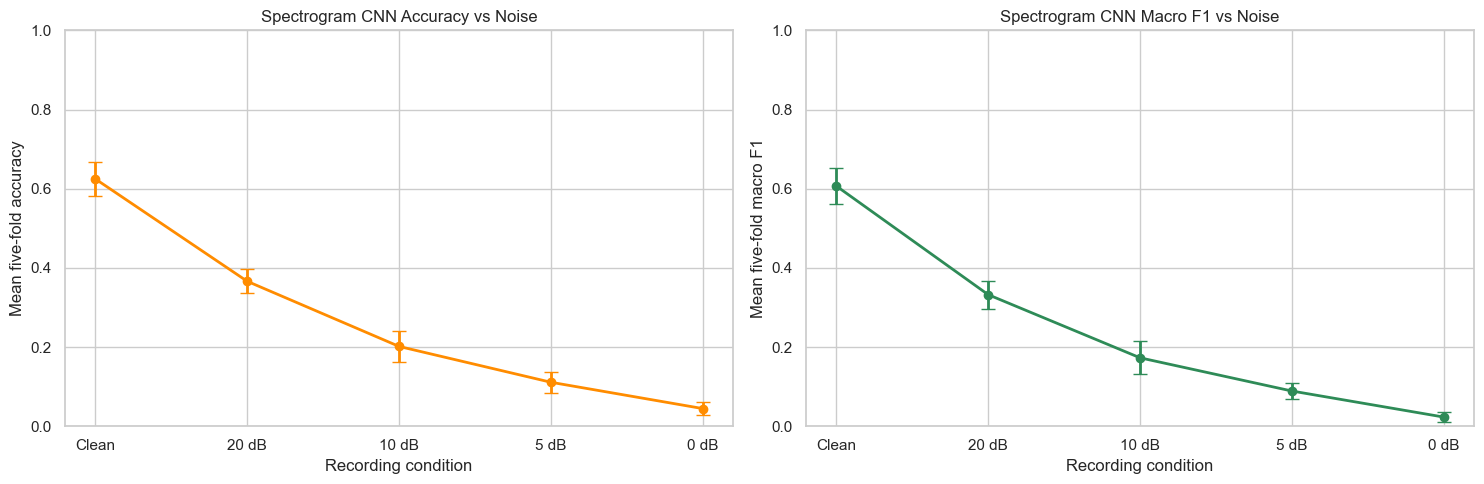

In [27]:
x_positions = np.arange(
    len(condition_order)
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5),
)

axes[0].errorbar(
    x_positions,
    noise_summary["mean_accuracy"],
    yerr=noise_summary["accuracy_std"],
    marker="o",
    linewidth=2,
    capsize=5,
    color="darkorange",
)

axes[0].set_xticks(
    x_positions
)

axes[0].set_xticklabels(
    condition_order
)

axes[0].set(
    title="Spectrogram CNN Accuracy vs Noise",
    xlabel="Recording condition",
    ylabel="Mean five-fold accuracy",
    ylim=(0, 1),
)


axes[1].errorbar(
    x_positions,
    noise_summary["mean_macro_f1"],
    yerr=noise_summary["macro_f1_std"],
    marker="o",
    linewidth=2,
    capsize=5,
    color="seagreen",
)

axes[1].set_xticks(
    x_positions
)

axes[1].set_xticklabels(
    condition_order
)

axes[1].set(
    title="Spectrogram CNN Macro F1 vs Noise",
    xlabel="Recording condition",
    ylabel="Mean five-fold macro F1",
    ylim=(0, 1),
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR
    / "performance_vs_snr.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

## 14. Class-wise noise robustness

The heatmap shows the F1 score of every ESC-50 class under each recording condition.

Classes whose F1 scores decrease rapidly are particularly sensitive to background noise.

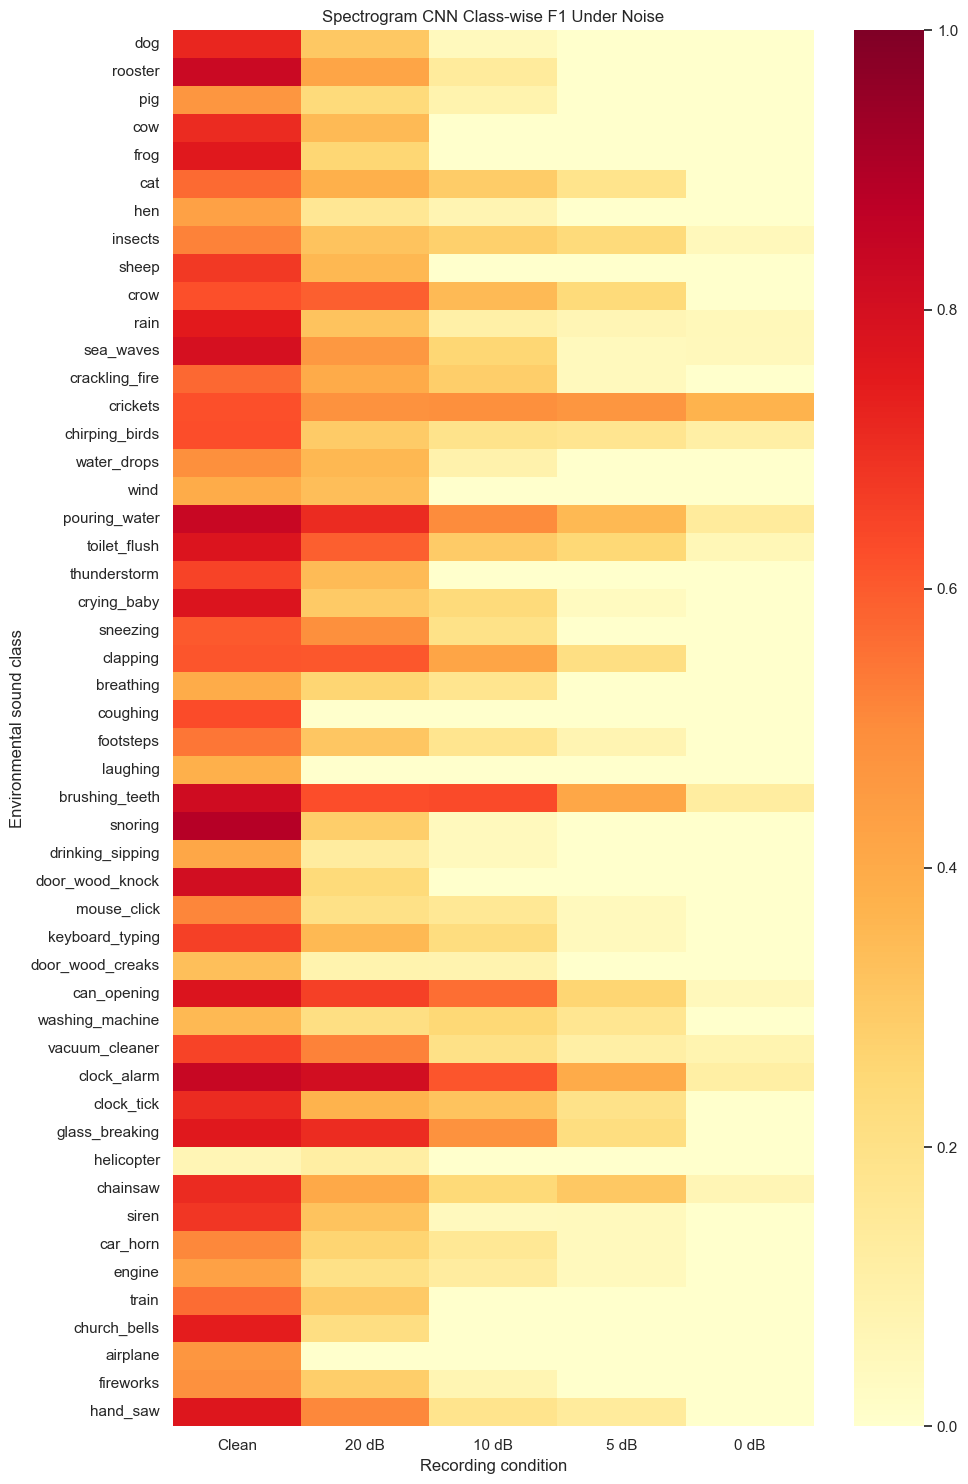

In [28]:
classwise_noise_f1 = pd.DataFrame(
    index=class_names
)

for condition_name in condition_order:
    predictions = condition_predictions[
        condition_name
    ]

    report = classification_report(
        y,
        predictions,
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )

    classwise_noise_f1[
        condition_name
    ] = [
        report[class_name]["f1-score"]
        for class_name in class_names
    ]

classwise_noise_f1.to_csv(
    OUTPUT_DIR
    / "classwise_f1_by_condition.csv"
)

fig, ax = plt.subplots(
    figsize=(10, 15)
)

sns.heatmap(
    classwise_noise_f1,
    cmap="YlOrRd",
    vmin=0,
    vmax=1,
    ax=ax,
)

ax.set(
    title="Spectrogram CNN Class-wise F1 Under Noise",
    xlabel="Recording condition",
    ylabel="Environmental sound class",
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR
    / "classwise_f1_noise_heatmap.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

## 15. Conclusion

The spectrogram CNN learns two-dimensional time-frequency patterns directly from audio spectrograms.

Its clean performance and noise-robustness results can now be compared against the MFCC and SVM solution.

Both solutions use:

- The same ESC-50 recordings
- The same five official folds
- Clean-only model training
- The same Gaussian-noise generation rule
- Clean, 20, 10, 5, and 0 dB evaluation conditions

The third solution will use pretrained audio embeddings with a lightweight classifier. This will test whether representations learned from a large external audio dataset generalize better to changing noise conditions.